# formula-search demo

`formula-search` looks for identifying formulas of a causal effect
$p(y \mid \operatorname{do}(t))$ in an acyclic directed mixed graph (ADMG).
It produces candidate formulas in several ways: existing identification
methods, templates, and a derivation search. An evaluator built on HiProF
judges every candidate. This notebook shows how to call each part and what
it returns:

1. Graphs and queries
2. Existing methods: ID, IDC, and equivalent queries
3. Templates
4. The evaluator
5. Comparing methods
6. Derivation search

Run it in the environment of `hiprof-eq`, after installing this package from
the repository root with `pip install -e .`. [PROGRESS.md](../PROGRESS.md)
describes the state of the code and the internals of the derivation search.

## 1. Graphs and queries

Graphs use hiprof's syntax. `->` is a directed edge, and `<->` is a
bidirected edge, which stands for a latent common cause. Here is the
front-door graph, with the treatment $T$ in blue and the outcome $Y$ in
orange:

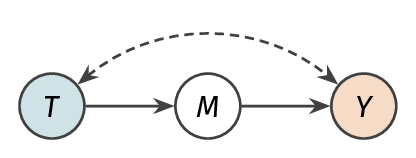

In [1]:
from formula_search.graph import ADMG

graph = ADMG.parse("T -> M; M -> Y; T <-> Y")
print(graph)
print(graph.complete())
graph.implies_constraints()

M -> Y; T -> M; T <-> Y
M -> Y; T -> M; T -> Y


False

`complete()` returns the complete DAG over the same variables. Its model
imposes no constraint on the observed law, so two formulas that agree on it
are the same function of the observed law. The evaluator uses this to tell
formulas apart. The front-door graph implies no equality constraint, so all
of its identifying formulas are one function.

A `Query` is $p(\text{outcomes} \mid \operatorname{do}(\text{treatments}),
\text{conditions})$. `equivalent_queries` returns the queries that Rules 2
and 3 of do-calculus prove equal to a query, each with a shortest path from
it. Together they form the connected component of the derivation graph of
Yvernes et al. (2026). On the napkin graph:

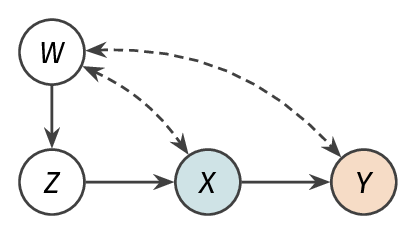

In [2]:
from formula_search.docalculus import Query, equivalent_queries

napkin = ADMG.parse("W -> Z; Z -> X; X -> Y; W <-> X; W <-> Y")
target = Query(outcomes=frozenset({"Y"}), treatments=frozenset({"X"}))

for path in equivalent_queries(napkin, target).values():
    print(" = ".join(map(str, path)))

p(Y | do(X))
p(Y | do(X)) = p(Y | do(W, X))
p(Y | do(X)) = p(Y | do(X, Z))
p(Y | do(X)) = p(Y | do(W, X)) = p(Y | do(W), X)
p(Y | do(X)) = p(Y | do(W, X)) = p(Y | do(W, X, Z))
p(Y | do(X)) = p(Y | do(X, Z)) = p(Y | do(Z), X)
p(Y | do(X)) = p(Y | do(W, X)) = p(Y | do(W), X) = p(Y | do(W, Z), X)
p(Y | do(X)) = p(Y | do(W, X)) = p(Y | do(W, X, Z)) = p(Y | do(W, X), Z)
p(Y | do(X)) = p(Y | do(W, X)) = p(Y | do(W), X) = p(Y | do(W, Z), X) = p(Y | do(W), X, Z)


## 2. Existing methods: ID, IDC, and equivalent queries

`identify` runs the ID algorithm. It returns a formula in hiprof's grammar,
or `None` when the target is not identifiable. HiProF checks the formula:

In [3]:
from hiprof import HPFalsifier

from formula_search.baselines import identify, identify_equivalent

formula = identify("T -> M; M -> Y; T <-> Y", treatments="T", outcomes="Y")
print(formula)
HPFalsifier("T -> M; M -> Y; T <-> Y").check("p(Y | do(T))", formula)

sum_{M} { p(M | T) sum_{T'} { p(T') p(Y | M, T') } }


True
False-acceptance bound: 5.421e-18

The check is randomized. A rejection is exact, because HiProF exhibits a
model on which the two sides differ. An acceptance holds up to the printed
false-acceptance bound, relative to HiProF's linear Gaussian models.

With `conditions`, `identify` runs IDC. The bow arc $T \to Y$, $T
\leftrightarrow Y$ has no identifying formula:

In [4]:
print(identify("T -> M; M -> Y; T <-> Y", "T", "Y", conditions="M"))
print(identify("T -> Y; T <-> Y", "T", "Y"))

sum_{T'} { p(T') p(Y | M, T') }
None


`identify_equivalent` implements the method of Yvernes et al. It applies IDC
to every query in the component of the target, and averages out the inputs
that the target lacks. It returns one formula per query. On the napkin
graph, all nine queries give ID's formula:

In [5]:
formulas = identify_equivalent(
    "W -> Z; Z -> X; X -> Y; W <-> X; W <-> Y", "X", "Y"
)
print(len(formulas), "queries")
set(formulas.values())

9 queries


{'sum_{Z} { p(Z | X) icd_{X | Z} { sum_{W} { p(W) p(X, Y | W, Z) } } }'}

## 3. Templates

`template_formulas` fills the slots of four templates with disjoint sets of
the other variables, in every way. The templates are adjustment, front-door,
front-door with adjustment, and napkin. Each formula comes with the template
and slots that give it. Most candidates are not valid, and the evaluator
sorts them out.

In [6]:
from formula_search.baselines import template_formulas

template_formulas("T -> M; M -> Y; T <-> Y", "T", "Y")

{'p(Y | T)': 'adjustment: S = {}',
 'sum_{M} { p(M) p(Y | M, T) }': 'adjustment: S = {M}',
 'p(Y)': 'front-door: S = {}',
 "sum_{M} { p(M | T) sum_{T'} { p(T') p(Y | M, T') } }": 'front-door: S = {M}'}

## 4. The evaluator

A `Task` is a graph with a treatment and an outcome. An `Archive` keeps one
formula per class of valid formulas for a task. Two formulas are in one class
if HiProF finds them equal on the complete DAG. `submit` returns a
`Verdict`, whose `outcome` is `malformed`, `falsified`, `duplicate`, or
`new`. Here is the graph with two adjustment sets, $\{Z_1\}$ and
$\{Z_1, Z_2\}$:

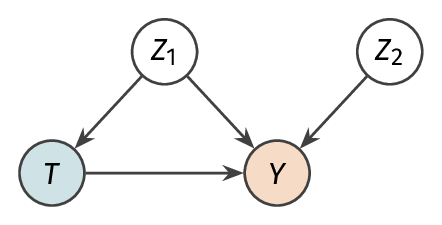

In [7]:
from formula_search.evaluator import Archive, Task

task = Task("Z1 -> T; Z1 -> Y; T -> Y; Z2 -> Y", treatment="T", outcome="Y")
archive = Archive(task)

candidates = {
    "adjustment for Z1": "sum_{Z1} { p(Z1) p(Y | T, Z1) }",
    "adjustment for Z1, Z2": "sum_{Z1, Z2} { p(Z1, Z2) p(Y | T, Z1, Z2) }",
    "a rewrite of the first": "sum_{Z1} { p(Z1) (p(Y, T, Z1) / p(T, Z1)) }",
    "no adjustment": "p(Y | T)",
    "an extra input": "p(Y | T, Z1)",
}
for source, formula in candidates.items():
    verdict = archive.submit(formula, source)
    print(f"{source:24} {verdict.outcome:10} {verdict.class_index}")

adjustment for Z1        new        0
adjustment for Z1, Z2    new        1
a rewrite of the first   duplicate  0
no adjustment            falsified  None
an extra input           malformed  None


A malformed formula records why. Every verdict goes to `archive.log`, in
order:

In [8]:
archive.log[-1]

Verdict(formula='p(Y | T, Z1)', source='an extra input', outcome='malformed', class_index=None, reason='The formula must be observational and of type Y | T.')

Each class keeps its first formula, HiProF's evidence, and its assumption
profile: the single edges whose addition to the graph breaks the formula.
Adding $Z_2 \to T$ breaks adjustment for $Z_1$ alone, but not for both.
`archive.checks` counts HiProF calls, for a union bound on false
acceptances.

In [9]:
for index, known in enumerate(archive.classes):
    print(index, known.formula)
    print("  broken by", ", ".join(sorted(known.broken_by)))
print("HiProF checks:", archive.checks)

0 sum_{Z1} { p(Z1) p(Y | T, Z1) }
  broken by T <-> Y, T <-> Z2, Z2 -> T
1 sum_{Z1, Z2} { p(Z1, Z2) p(Y | T, Z1, Z2) }
  broken by T -> Z2, T <-> Y
HiProF checks: 26


## 5. Comparing methods

Submitting the formulas of several methods to one archive compares them. The
first verdict of each class names the method that found it. Here, ID on
equivalent queries, the baseline archive B of the plan, is compared with
the templates on the same task:

In [10]:
archive = Archive(task)
for query, formula in identify_equivalent(*task).items():
    archive.submit(formula, f"IDC on {query}")
for formula, source in template_formulas(*task).items():
    archive.submit(formula, source)

found_by = {v.class_index: v.source for v in archive.log if v.outcome == "new"}
for index, known in enumerate(archive.classes):
    print(f"{index}  {found_by[index]:28} {known.formula}")

0  IDC on p(Y | do(T))          sum_{Z1, Z2} { p(Z1) p(Z2) p(Y | T, Z1, Z2) }
1  adjustment: S = {Z1}         sum_{Z1} { p(Z1) p(Y | T, Z1) }
2  adjustment: S = {Z1, Z2}     sum_{Z1, Z2} { p(Z1, Z2) p(Y | T, Z1, Z2) }
3  napkin: Z = {Z1}, W = {Z2}   sum_{Z1} { p(Z1) icd_{T | Z1} { sum_{Z2} { p(Z2) p(T, Y | Z1, Z2) } } }


ID's class 0 and the adjustment class 2 differ only in $p(Z_1)\,p(Z_2)$
against $p(Z_1, Z_2)$. They are equal in this graph, since $Z_1$ and $Z_2$
are independent, but they are different functions on the complete DAG, so
the evaluator counts two classes. What should count as a substantively
different formula is open question Q-006 of the plan.

The same comparison on the curated tasks of the plan, the larger ones
excluded, shows how many classes the templates add to B:

In [11]:
from formula_search.suite import CURATED

for name in [
    "front-door",
    "napkin",
    "confounder and mediator",
    "collider and mediator",
    "front-door (ii)",
    "adjustment-rich",
]:
    task = CURATED[name]
    archive = Archive(task)
    for formula in identify_equivalent(*task).values():
        archive.submit(formula, "B")
    b = len(archive.classes)
    for formula, source in template_formulas(*task).items():
        archive.submit(formula, source)
    print(f"{name:24} B: {b}   templates beyond B: {len(archive.classes) - b}")

front-door               B: 1   templates beyond B: 0
napkin                   B: 1   templates beyond B: 1
confounder and mediator  B: 1   templates beyond B: 2
collider and mediator    B: 1   templates beyond B: 1
front-door (ii)          B: 1   templates beyond B: 13
adjustment-rich          B: 2   templates beyond B: 36


`CURATED` holds the curated tasks of the plan. `random_tasks` draws
reproducible random tasks, keeping graphs on which ID identifies the target:

In [12]:
from formula_search.suite import random_tasks

random_tasks(3, size=6, density=0.5, seed=1)

[Task(graph='A -> B; A -> C; A -> D; B -> Y; D -> B; T -> D; A <-> Y', treatment='T', outcome='Y'),
 Task(graph='A -> Y; B -> Y; C -> A; C -> B; C -> D; D -> A; D -> B; D -> Y; T -> C; A <-> D; B <-> T; T <-> Y', treatment='T', outcome='Y'),
 Task(graph='B -> A; C -> T; T -> A; T -> B; T -> Y; A <-> C; B <-> D; C <-> T', treatment='T', outcome='Y')]

## 6. Derivation search

`derive(graph, treatments, outcomes, bound)` searches derivations of the
target. It uses Rules 2 and 3 of do-calculus, which are free, and three
rules of probability, each of which costs 1: marginalization, conditioning,
and the chain rule. `bound` caps the cost. The result is one `Derivation`
per class of the target found, in order of cost.
[PROGRESS.md](../PROGRESS.md#derivation-search) explains the algorithm.

In [13]:
from formula_search.derivation import derive

(derivation,) = derive(*CURATED["front-door"], bound=4)
derivation.formula

"sum_{M} { p(M | T) sum_{T'} { p(T') p(Y | M, T') } }"

A `Derivation` is a tree of rules, with the fields `query`, `rule`, and
`premises`. A do-calculus step also has the `path` of queries it follows
and, if needed, a `weight`. This helper prints the tree, one rule per line,
and counts its cost:

In [14]:
from formula_search.derivation import Derivation
from formula_search.expression import render_query

PROBABILITY_RULES = {"marginalization", "conditioning", "chain rule"}


def show(derivation: Derivation, depth: int = 0) -> None:
    """Print a derivation as a tree, one rule per line."""
    line = f"{'  ' * depth}{derivation.query}  [{derivation.rule}]"
    if derivation.rule == "do-calculus":
        line += "  " + " = ".join(map(str, derivation.path[1:]))
        (premise,) = derivation.premises
        if extra := premise.expression.inputs - derivation.query.inputs:
            weight = render_query(extra, conditions=derivation.weight)
            line += f", weight {weight}"
    print(line)
    for premise in derivation.premises:
        show(premise, depth + 1)


def cost(derivation: Derivation) -> int:
    """Count the rules of probability in a derivation."""
    own = derivation.rule in PROBABILITY_RULES
    return own + sum(map(cost, derivation.premises))


show(derivation)
cost(derivation)

p(Y | do(T))  [marginalization]
  p(M, Y | do(T))  [chain rule]
    p(M | do(T))  [do-calculus]  p(M | T)
      p(M | T)  [base]
    p(Y | do(T), M)  [do-calculus]  p(Y | do(M, T)) = p(Y | do(M))
      p(Y | do(M))  [marginalization]
        p(T, Y | do(M))  [chain rule]
          p(T | do(M))  [do-calculus]  p(T)
            p(T)  [base]
          p(Y | do(M), T)  [do-calculus]  p(Y | M, T)
            p(Y | M, T)  [base]


4

Read the tree from the top. The search marginalizes $M$ and splits
$p(M, Y \mid \operatorname{do}(T))$ by the chain rule. Then
$p(M \mid \operatorname{do}(T)) = p(M \mid T)$ by Rule 2, and
$p(Y \mid \operatorname{do}(T), M) = p(Y \mid \operatorname{do}(M))$ by
Rules 2 and 3. Finally $p(Y \mid \operatorname{do}(M))$ is adjusted for $T$
in the same way. This is the textbook derivation of the front-door formula,
and its four rules of probability give its cost.

On the napkin graph the search finds two classes. Both average $Z$ out of
the same kernel, one with the weight $p(Z)$ and one with $p(Z \mid X)$. The
napkin's Verma constraint makes them different functions:

In [15]:
napkin_task = CURATED["napkin"]
derivations = derive(*napkin_task, bound=3)
for d in derivations:
    print(d.formula)
print()
show(derivations[1])

sum_{Z} { p(Z) icd_{X | Z} { sum_{W} { p(W) p(X, Y | W, Z) } } }
sum_{Z} { p(Z | X) icd_{X | Z} { sum_{W} { p(W) p(X, Y | W, Z) } } }

p(Y | do(X))  [do-calculus]  p(Y | do(X, Z)) = p(Y | do(Z), X), weight p(Z | X)
  p(Y | do(Z), X)  [marginalization]
    p(W, Y | do(Z), X)  [conditioning]
      p(W, X, Y | do(Z))  [chain rule]
        p(W | do(Z))  [do-calculus]  p(W)
          p(W)  [base]
        p(X, Y | do(Z), W)  [do-calculus]  p(X, Y | W, Z)
          p(X, Y | W, Z)  [base]


`verify` replays a derivation, testing every rule and side condition again
in the graph. A formula submitted with its derivation is derivation-certified.
ID's formula is a duplicate of one of the two classes:

In [16]:
napkin_graph = ADMG.parse(napkin_task.graph)
print([d.verify(napkin_graph) for d in derivations])

archive = Archive(napkin_task)
for d in derivations:
    verdict = archive.submit(d.formula, d)
    print(verdict.outcome, verdict.class_index, verdict.certified)
archive.submit(identify(*napkin_task), "ID")

[True, True]
new 0 True
new 1 True


Verdict(formula='sum_{Z} { p(Z | X) icd_{X | Z} { sum_{W} { p(W) p(X, Y | W, Z) } } }', source='ID', outcome='duplicate', class_index=1, reason='')

The search can find formulas that ID does not. On the split-product graph of
Freni et al. (2026, Example 7), ID returns a long formula. At cost 4 the
search finds the front-door formula over $A$, which is valid and a different
class:

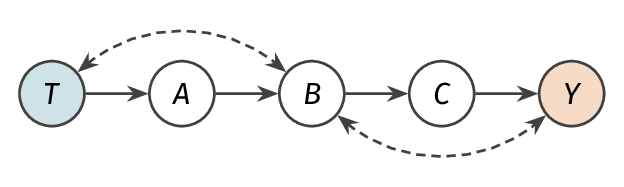

In [17]:
split = CURATED["split product"]
print("ID:     ", identify(*split))
(found,) = derive(*split, bound=4)
print("derived:", found.formula)

archive = Archive(split)
[archive.submit(f).outcome for f in (identify(*split), found.formula)]

ID:      sum_{A, B, C} { p(A | T) sum_{T'} { p(T') p(B | A, T') } p(C | A, B, T) icd_{B | A, C} { sum_{T'} { p(T') p(B | A, T') p(Y | A, B, C, T') } } }
derived: sum_{A} { p(A | T) sum_{T'} { p(T') p(Y | A, T') } }


['new', 'new']

The number of classes grows fast with the bound wherever the graph implies
independences. On the graph with two adjustment sets, the search finds 2
classes at cost 2, 2 at cost 3, and 173 at cost 4, which takes about one and
a half minutes:

In [18]:
for d in derive(*CURATED["two adjustment sets"], bound=3):
    print(cost(d), d.formula)

2 sum_{Z1} { p(Z1) p(Y | T, Z1) }
2 sum_{Z1} { sum_{Z2} { p(Z2 | T) p(Z1 | Z2) } p(Y | T, Z1) }
3 sum_{Z1, Z2} { p(Z1, Z2) p(Y | T, Z1, Z2) }
3 sum_{Z1} { sum_{Y'} { p(Y' | T) sum_{Z2} { p(Z2 | Y') p(Z1 | Z2) } } p(Y | T, Z1) }


The second formula writes $p(Z_1)$ as
$\sum_{z_2} p(z_2 \mid T)\, p(Z_1 \mid z_2)$. This holds in the graph
because $Z_1$ and $Z_2$ are independent, but it is a different function on
the complete DAG. Most of the 173 classes at cost 4 are variants
of this kind. Deciding which of them count as different formulas is the
main open question before the search is scaled; see
[PROGRESS.md](../PROGRESS.md#next-steps).